## Example of opening a OSTIA Icechunk v2 store

#### Python environment

icechunk == 2.1.2

xarray == 2026.7.0

earthaccess == 0.18.0

zarr == 3.2.1

In [ ]:
#!pip install "icechunk==2.1.2"

In [21]:
!pip list | grep -E "icec|^xarray|earth|^zarr"

earthaccess               0.18.0
icechunk                  2.1.2
xarray                    2026.7.0
zarr                      3.2.1


In [22]:
import icechunk
import xarray as xr
import earthaccess
import os

In [23]:
import os
import icechunk
import xarray as xr
import earthaccess

# --- 1. Get Earthdata Bearer Token ---
earthaccess.login()

# Extract the Bearer token directly from the authenticated session
edl_token = earthaccess.get_edl_token()
#print(edl_token['access_token'])

# --- 2. Configure HTTP Storage for the Icechunk Metadata ---
repo_url = (
    "https://archive.podaac.uat.earthdata.nasa.gov/podaac-uat-cumulus-public/"
    "virtual_collections/OSTIA-UKMO-L4-GLOB-REP-v2.0/OSTIA-UKMO-L4-GLOB-REP-v2.0.icechunk_v2.https"
)

storage = icechunk.http_storage(repo_url)

# --- 3. Override the Repository Config for the Virtual Chunks ---
config = icechunk.Repository.fetch_config(storage)

# Match the FULL prefix the chunks actually resolve to (see the error message)
https_prefix = "https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/"

https_store = icechunk.http_store(
    headers={"Authorization": f"Bearer {edl_token['access_token']}"}
)

config.set_virtual_chunk_container(
    icechunk.VirtualChunkContainer(https_prefix, https_store)
)

# --- 4. Authorize and Open Repo ---
auth_map = {
    https_prefix: icechunk.credentials.HttpAccess
}

repo = icechunk.Repository.open(
    storage,
    config=config,
    authorize_virtual_chunk_access=auth_map
)

# --- 5. Load the Dataset ---
session = repo.readonly_session("main")
ds = xr.open_zarr(session.store, consolidated=False)

print("Successfully loaded dataset using 100% pure HTTPS!")
print(ds)

Successfully loaded dataset using 100% pure HTTPS!
<xarray.Dataset> Size: 3TB
Dimensions:           (time: 3653, lat: 3600, lon: 7200)
Coordinates:
  * time              (time) datetime64[ns] 29kB 1989-12-31T12:00:00 ... 1999...
  * lat               (lat) float32 14kB -89.97 -89.93 -89.88 ... 89.93 89.97
  * lon               (lon) float32 29kB -180.0 -179.9 -179.9 ... 179.9 180.0
Data variables:
    analysed_sst      (time, lat, lon) float64 757GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    analysis_error    (time, lat, lon) float64 757GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    mask              (time, lat, lon) float32 379GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    sea_ice_fraction  (time, lat, lon) float64 757GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
Attributes: (12/48)
    Conventions:                CF-1.4, ACDD-1.3
    title:                      Global SST & Sea Ice Analysis, L4 OSTIA, 0.05...
    summary:     

Plot SST time step 


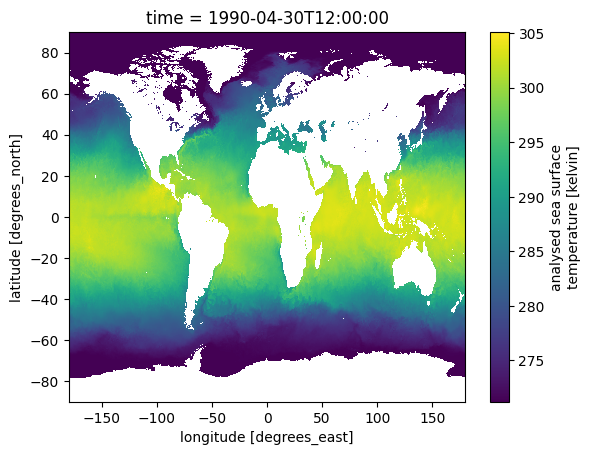

In [24]:
print("Plot SST time step ")
ds.analysed_sst.isel(time=120).plot()

In [25]:
# Do some spatial/temporal subsetting, averaging and re sampling

# Define region 
# Gulf of Tehuantepec, MX
lat_min = 14.
lat_max = 15.
lon_min = -96.
lon_max = -95.

lat_range = (lat_min, lat_max)
lon_range = (lon_min, lon_max)

# for datasets that use 0-360 deg lon
lon_range_360 = (lon_min+360, lon_max+360)

# Define the time slice 
start_date = '1990-01-01'
#end_date = '1998-12-31'
end_date = '1990-12-31'
#end_date = '1994-12-31'
time_range =(start_date, end_date)


In [26]:
%%time
# A concise method to subset, resample, and average the xarray data all on one line
sst_resample = ds.analysed_sst.sel(lon=slice(*lon_range), lat=slice(*lat_range), time=slice(*time_range)
).mean(["lat", "lon"]).resample(time="1ME").mean().load()

CPU times: user 12.7 s, sys: 2.12 s, total: 14.8 s
Wall time: 42 s


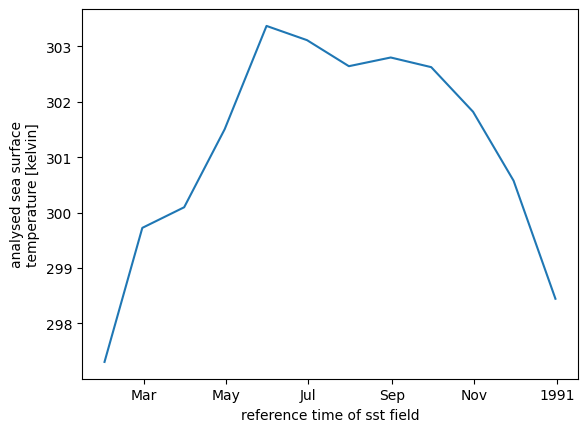

In [27]:
sst_resample.plot()